In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "ml":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.src.train_discount_model import *

print("Project root:", PROJECT_ROOT)
print("Discount Model notebook setup completed!")

Project root: d:\machine learning_project\WasteWise-AI\WasteWise-AI
Discount Model notebook setup completed!


In [2]:
#dataset load

from ml.src.train_discount_model import prepare_discount_data

discount_df, numeric_features, categorical_features = prepare_discount_data()

print("Dataset shape:", discount_df.shape)
print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

display(discount_df.head(10))

Dataset shape: (10000, 10)

Numeric features: ['days_to_expiry', 'quantity_remaining', 'discount_pct', 'shelf_life_days', 'selling_price', 'unit_cost']

Categorical features: ['product_id', 'category']


,batch_id,estimated_gross_margin_simulated,days_to_expiry,quantity_remaining,discount_pct,shelf_life_days,selling_price,unit_cost,product_id,category
0,5001,1224.00,5,72,0,7,45.0,28.0,1006,Produce
1,5001,1062.00,5,72,5,7,45.0,28.0,1006,Produce
2,5001,900.00,5,72,10,7,45.0,28.0,1006,Produce
3,5001,738.00,5,72,15,7,45.0,28.0,1006,Produce
4,5001,576.00,5,72,20,7,45.0,28.0,1006,Produce
5,5002,629.00,1,123,0,7,45.0,28.0,1006,Produce
6,5002,604.75,1,123,5,7,45.0,28.0,1006,Produce
7,5002,575.00,1,123,10,7,45.0,28.0,1006,Produce
8,5002,522.75,1,123,15,7,45.0,28.0,1006,Produce
9,5002,440.00,1,123,20,7,45.0,28.0,1006,Produce


In [3]:
#Train-Test Split

from ml.src.training_common import chronological_split

TARGET = "estimated_gross_margin_simulated"

train_df, test_df, cutoff = chronological_split(
    discount_df, "batch_id"
)

feature_columns = numeric_features + categorical_features

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df[TARGET]
y_test = test_df[TARGET]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Split cutoff:", cutoff)

print("\nTarget statistics:")
print(y_train.describe())

Training rows: 8000
Testing rows: 2000
Split cutoff: 1970-01-01 00:00:00.000006601

Target statistics:
count    8000.000000
mean      226.211050
std       399.164549
min         0.000000
25%         0.000000
50%         0.000000
75%       300.000000
max      3486.000000
Name: estimated_gross_margin_simulated, dtype: float64


In [4]:
#Model train

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(discount_df, groups=discount_df["batch_id"])
)

train_df = discount_df.iloc[train_idx].copy()
test_df = discount_df.iloc[test_idx].copy()

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]
y_train = train_df[TARGET]
y_test = test_df[TARGET]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Overlapping batches:", len(set(train_df["batch_id"]) & set(test_df["batch_id"])))

Training rows: 8000
Testing rows: 2000
Overlapping batches: 0


In [5]:
#Discount Recommendation Model Train

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

discount_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

discount_model.fit(X_train, y_train)

print("Discount Recommendation Model trained successfully!")

Discount Recommendation Model trained successfully!


In [7]:
#Model Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

discount_predictions = discount_model.predict(X_test)

mae = mean_absolute_error(y_test, discount_predictions)
rmse = np.sqrt(mean_squared_error(y_test, discount_predictions))
r2 = r2_score(y_test, discount_predictions)

print("Discount Recommendation Model Evaluation")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")

Discount Recommendation Model Evaluation
MAE: 36.543
RMSE: 97.360
R2 Score: 0.944


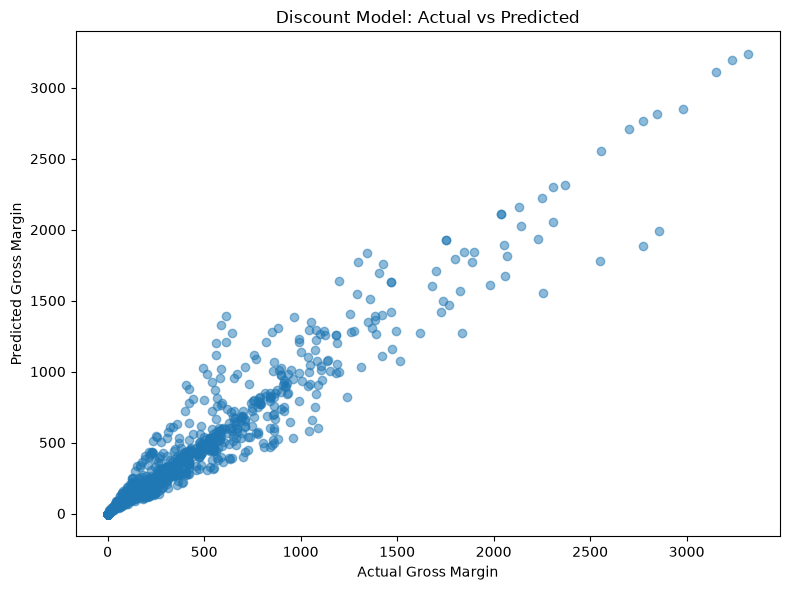

In [8]:
#Actual vs Predicted Graph

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    discount_predictions,
    alpha=0.5
)

plt.xlabel("Actual Gross Margin")
plt.ylabel("Predicted Gross Margin")
plt.title("Discount Model: Actual vs Predicted")

plt.tight_layout()
plt.show()

In [9]:
#Actual vs Predicted Results Table

discount_results = test_df[
    ["batch_id", "product_id", "category", "discount_pct",
     "estimated_gross_margin_simulated"]
].copy()

discount_results["predicted_gross_margin"] = discount_predictions.round(2)

discount_results = discount_results.rename(
    columns={
        "estimated_gross_margin_simulated": "actual_gross_margin"
    }
)

display(discount_results.head(20))

,batch_id,product_id,category,discount_pct,actual_gross_margin,predicted_gross_margin
115,5024,1010,Bakery,0,0.0,0.00
116,5024,1010,Bakery,5,0.0,0.00
117,5024,1010,Bakery,10,0.0,0.00
118,5024,1010,Bakery,15,0.0,0.00
119,5024,1010,Bakery,20,0.0,0.00
145,5030,1006,Produce,0,1190.0,1056.60
146,5030,1006,Produce,5,1150.5,1004.71
147,5030,1006,Produce,10,1050.0,914.10
148,5030,1006,Produce,15,861.0,756.55
149,5030,1006,Produce,20,672.0,600.58


In [10]:
#Best Discount

best_discount = (
    discount_results
    .loc[
        discount_results.groupby("batch_id")[
            "predicted_gross_margin"
        ].idxmax()
    ]
    .sort_values("batch_id")
    .reset_index(drop=True)
)

print("Best Discount Recommendation for Each Batch")
display(
    best_discount[
        [
            "batch_id",
            "product_id",
            "category",
            "discount_pct",
            "predicted_gross_margin"
        ]
    ].head(20)
)

Best Discount Recommendation for Each Batch


,batch_id,product_id,category,discount_pct,predicted_gross_margin
0,5024,1010,Bakery,0,0.00
1,5030,1006,Produce,0,1056.60
2,5031,1008,Beverage,0,0.00
3,5033,1004,Dairy,0,262.97
4,5045,1002,Dairy,0,521.38
5,5046,1008,Beverage,0,0.00
6,5050,1008,Beverage,0,0.00
7,5057,1002,Dairy,0,0.00
8,5060,1004,Dairy,0,0.00
9,5064,1008,Beverage,0,0.00


In [11]:
#Results save

from pathlib import Path

output_path = PROJECT_ROOT / "ml" / "artifacts" / "discount_notebook_results.csv"

best_discount.to_csv(output_path, index=False)

print("Results saved successfully!")
print("File location:", output_path)

Results saved successfully!
File location: d:\machine learning_project\WasteWise-AI\WasteWise-AI\ml\artifacts\discount_notebook_results.csv
